In [ ]:
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
import matplotlib.pyplot as plt
import sys
sys.path.append('..')
from pathlib import Path
from sklearn.metrics import (
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    fbeta_score,
    make_scorer,
    classification_report
)
from sklearn.inspection import permutation_importance
from src.preparacao import carregar_dados

caminho = Path('../data/TESTE_ML_COM_TAXAS_INFRA.csv')

df = carregar_dados(caminho)

df['enquadro'] = pd.NA

df.loc[df['evasao'] == 0.0, 'enquadro'] = 0

df.loc[df['evasao'] >= 0.1, 'enquadro'] = 1

df['enquadro'] = df['enquadro'].astype('Int64')

display(df.head())

,cod_municipio,nome_municipio,perc_doc_sobrecarga,taxa_informal,taxa_climatizacao,taxa_internet,taxa_lab,media_alunos_por_sala,renda_pc,evasao,tx_repet,enquadro
0,4201273,Arabutã,34.6,41.70,100,100.00,"71,43","15,1",2056.91,0.0,0.9,0
1,4201703,Ascurra,41.5,18.45,"63,64",54.55,"18,18","29,6",1713.62,3.9,4.8,1
2,4201950,Balneário Arroio do Silva,35.8,44.02,"87,5",75.00,"37,5","23,3",1530.60,3.0,2.3,1
3,4202578,Bom Jesus do Oeste,31.6,41.36,75,75.00,50,"8,7",2347.75,1.8,1.8,1
4,4203154,Calmon,17.4,30.26,"62,5",75.00,25,"22,2",1031.92,6.1,1.5,1


In [ ]:
colunas_ml = ['perc_doc_sobrecarga','taxa_informal','tx_repet','renda_pc',
              'taxa_internet']

x = df[colunas_ml]
y = df['enquadro']

X_train, X_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

pipeline = ImbPipeline([
    ('smote', SMOTE(random_state=42)),
    ('clf',   GradientBoostingClassifier(random_state=42))
])

param_grid = {
    'smote__k_neighbors':    [3, 5],           
    'clf__n_estimators':     [100, 200, 300],
    'clf__learning_rate':    [0.05, 0.1],
    'clf__max_depth':        [2, 3, 4],
    'clf__min_samples_leaf': [5, 10],
    'clf__subsample':        [0.8, 1.0],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

f2_scorer = make_scorer(fbeta_score, beta=2)

grid = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring=f2_scorer,       
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Melhores parâmetros:", grid.best_params_)
print(f"Melhor F2 (CV 5-fold): {grid.best_score_:.4f}")

Fitting 5 folds for each of 144 candidates, totalling 720 fits
Melhores parâmetros: {'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__min_samples_leaf': 5, 'clf__n_estimators': 200, 'clf__subsample': 1.0, 'smote__k_neighbors': 3}
Melhor F2 (CV 5-fold): 0.9019


   Threshold  Recall (Sensibilidade)  Precisão  F2-Score
0        0.5                  0.8491    0.9184    0.8621
1        0.4                  0.9245    0.9245    0.9245
2        0.3                  0.9434    0.9259    0.9398
3        0.2                  0.9434    0.9091    0.9363

Métricas finais:


,Métrica,Valor
0,F2-Score,86.21%
1,Acurácia,79.66%
2,Precisão,91.84%
3,Recall,84.91%


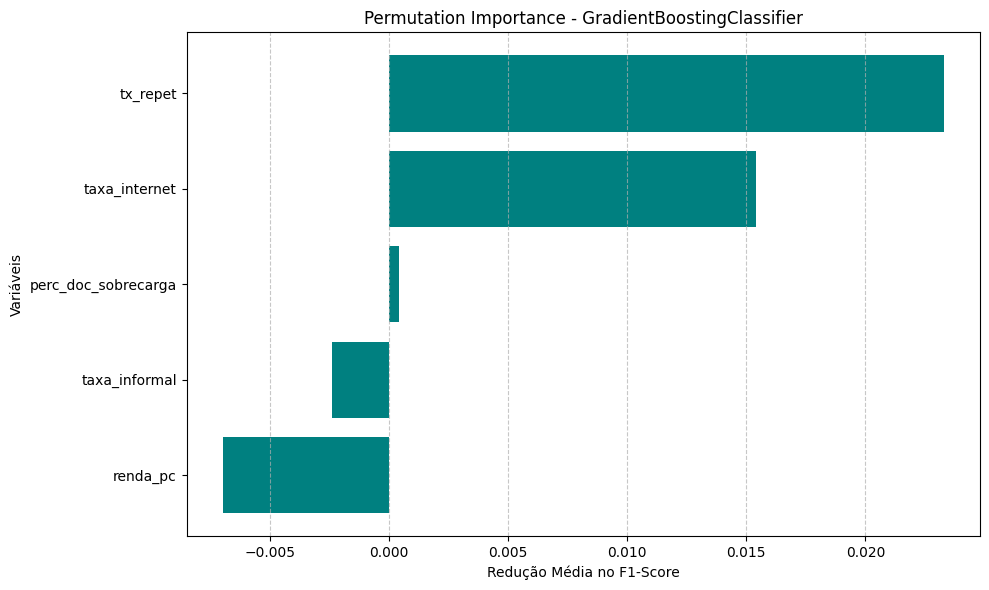

In [ ]:
melhor_modelo = grid.best_estimator_

melhor_modelo.fit(X_train, y_train)

y_pred = melhor_modelo.predict(X_test)

metricas_finais = pd.DataFrame({
    'Métrica': [
        'F2-Score',
        'Acurácia',
        'Precisão',
        'Recall'
    ],
    'Valor': [
        fbeta_score(y_test, y_pred,beta=2, zero_division=0),
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0)
    ]
})

metricas_finais['Valor'] = metricas_finais['Valor'].apply( lambda x: f'{x * 100:.2f}%' )

print('\nMétricas finais:')
display(metricas_finais)

permutation = permutation_importance(
    melhor_modelo,
    X_test,
    y_test,
    scoring=f2_scorer,
    n_repeats=30,
    random_state=42,
    n_jobs=-1
)

tabela_permutation_importance = pd.DataFrame({
    'Variável': X_test.columns,
    'Importância média': permutation.importances_mean,
    'Desvio padrão': permutation.importances_std
}).sort_values(
    by='Importância média',
    ascending=True
).reset_index(drop=True)

tabela_permutation_importance['Importância média'] = (
    tabela_permutation_importance['Importância média'].round(4)
)

tabela_permutation_importance['Desvio padrão'] = (
    tabela_permutation_importance['Desvio padrão'].round(4)
)


plt.figure(figsize=(10, 6))
plt.barh(
    tabela_permutation_importance['Variável'],
    tabela_permutation_importance['Importância média'],
    color='teal'
)
plt.title('Permutation Importance - GradientBoostingClassifier')
plt.xlabel('Redução Média no F1-Score')
plt.ylabel('Variáveis')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()
